In [67]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors

plt.style.use('dark_background')

In [14]:
students = pd.read_csv('datos//StudentsPerformance.csv')
students

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [4]:
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
# preprocessing, NaN, outliers, duplicates
# statistics report (insights)

In [39]:
students['calificacion'] = (students['math score']+students['reading score']+students['writing score'])/30
students['aprobo'] = np.where(students['calificacion']>=6, True, False)
students

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,aprobo,calificacion
0,female,group B,bachelor's degree,standard,none,72,72,74,True,7.266667
1,female,group C,some college,standard,completed,69,90,88,True,8.233333
2,female,group B,master's degree,standard,none,90,95,93,True,9.266667
3,male,group A,associate's degree,free/reduced,none,47,57,44,False,4.933333
4,male,group C,some college,standard,none,76,78,75,True,7.633333
...,...,...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95,True,9.400000
996,male,group C,high school,free/reduced,none,62,55,55,False,5.733333
997,female,group C,high school,free/reduced,completed,59,71,65,True,6.500000
998,female,group D,some college,standard,completed,68,78,77,True,7.433333


In [40]:
aprobo = students['aprobo'].mean()
reprobo = 1 - aprobo
print(aprobo, reprobo)

0.715 0.28500000000000003


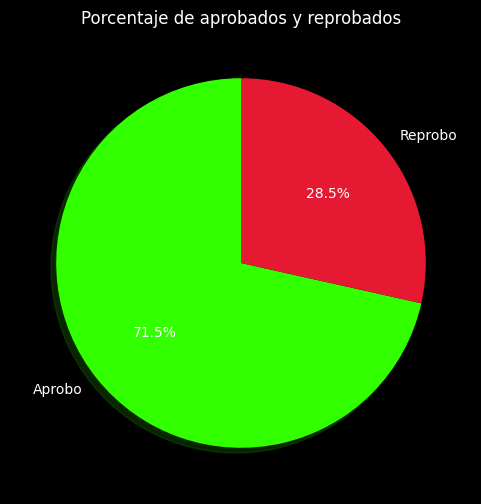

In [42]:
labels = ['Aprobo', 'Reprobo']
size = [aprobo, reprobo]

fig = plt.figure(figsize=(6, 6))
plt.pie(size, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#32FF00', '#E51932'], shadow=True)
plt.title('Porcentaje de aprobados y reprobados')
plt.show()

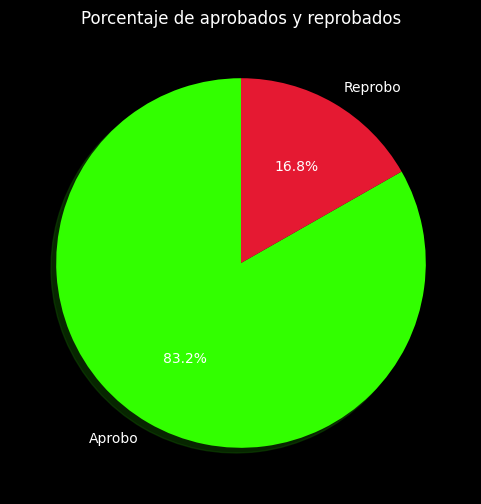

In [ ]:
aprobo = students[students['test preparation course']=='completed']['aprobo'].mean()
reprobo = 1 - aprobo
labels = ['Aprobo', 'Reprobo']
size = [aprobo, reprobo]

fig = plt.figure(figsize=(6, 6))
plt.pie(size, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#32FF00', '#E51932'], shadow=True)
plt.title('Porcentaje de aprobados y reprobados, con test completo')
plt.show()

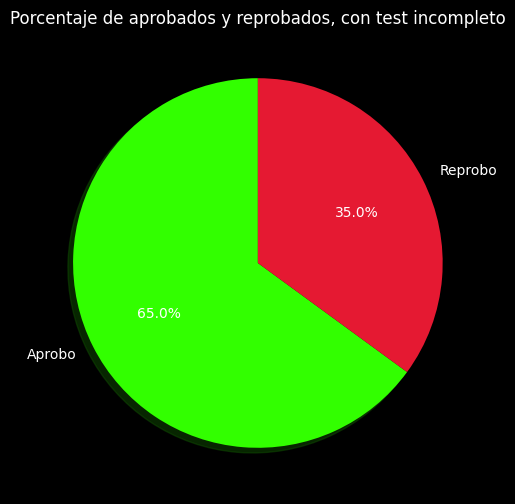

In [55]:
aprobo = students[students['test preparation course']!='completed']['aprobo'].mean()
reprobo = 1 - aprobo
labels = ['Aprobo', 'Reprobo']
size = [aprobo, reprobo]

fig = plt.figure(figsize=(6, 6))
plt.pie(size, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#32FF00', '#E51932'], shadow=True)
plt.title('Porcentaje de aprobados y reprobados, con test incompleto')
plt.show()

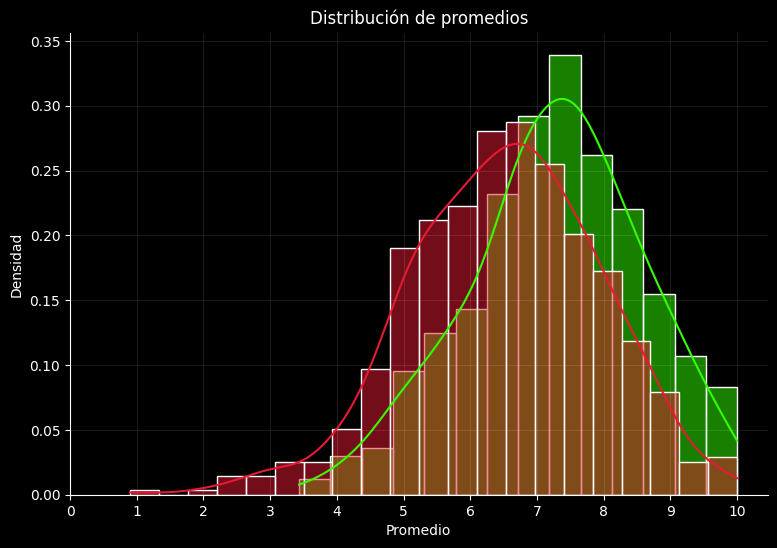

In [66]:
fig = plt.figure(figsize=(9, 6))
#sns.histplot(data=students, x='calificacion', color= '#1AB2FF',stat="density", kde=True, alpha=0.5)
sns.histplot(data=students[students['test preparation course']=='completed'], x='calificacion', color = '#33FF00',stat="density", kde=True, alpha=0.5)
sns.histplot(data=students[students['test preparation course']!='completed'], x='calificacion', color = '#E61A33',stat="density", kde=True, alpha=0.5)
plt.title('Distribución de promedios')
#plt.axvline(x=6, color='red')
plt.xlabel('Promedio')
plt.xticks([x for x in range(11)])
plt.ylabel('Densidad')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(alpha=0.1)
plt.show()

In [71]:
datos = students['calificacion']
stat_ks, p_ks = lilliefors(datos, dist='norm')
print(f"Lilliefors (K-S) -> Estadístico: {stat_ks:.4f}, p-valor: {p_ks:.4f}")
alpha = 0.05
if p_ks > alpha:
    print("No se rechaza H0: Los datos parecen seguir una distribución normal.")
else:
    print("Se rechaza H0: Los datos NO siguen una distribución normal.")

Lilliefors (K-S) -> Estadístico: 0.0324, p-valor: 0.0215
Se rechaza H0: Los datos NO siguen una distribución normal.


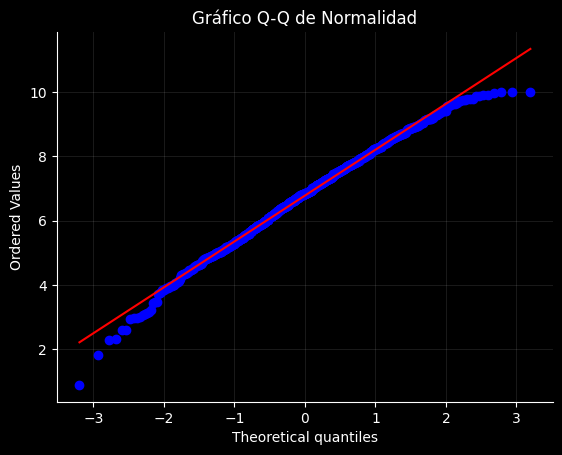

In [72]:
stats.probplot(datos, dist="norm", plot=plt)
plt.title("Gráfico Q-Q de Normalidad")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(alpha=0.1)
plt.show()

In [9]:
students['test preparation course'].unique()

array(['none', 'completed'], dtype=object)

In [12]:
subjects_scores = ['test preparation course', 'math score', 'reading score', 'writing score']
students = students[subjects_scores]
students = students[students['test preparation course']=='completed']
students

,test preparation course,math score,reading score,writing score
1,completed,69,90,88
6,completed,88,95,92
8,completed,64,64,67
13,completed,78,72,70
18,completed,46,42,46
...,...,...,...,...
990,completed,86,81,75
991,completed,65,82,78
995,completed,88,99,95
997,completed,59,71,65


In [13]:
students = students.drop_duplicates()
students

,test preparation course,math score,reading score,writing score
1,completed,69,90,88
6,completed,88,95,92
8,completed,64,64,67
13,completed,78,72,70
18,completed,46,42,46
...,...,...,...,...
990,completed,86,81,75
991,completed,65,82,78
995,completed,88,99,95
997,completed,59,71,65
